---

# <center> **Healthcare Management**  </center>

### <center> Patient Readmission Prediction </center>

--

## Project Introduction

This project focuses on analyzing healthcare encounter data to understand patterns associated with **30-day hospital readmission among patients with diabetes**.

The analysis uses the UCI Diabetes dataset, which contains information on patient demographics, hospital encounters, diagnoses, procedures, medications, and healthcare utilization.

Python is used in this phase to perform exploratory data analysis (EDA), identify important data patterns, examine relationships between variables, and support the understanding of factors associated with 30-day readmission.


## Business Problem

Hospital readmissions within 30 days of discharge are an important healthcare management concern because they may indicate complex patient needs and repeated healthcare utilization.

Healthcare organizations need to understand the characteristics and patterns associated with patients who are readmitted shortly after discharge.

The business problem addressed in this analysis is:

> **How can healthcare data be analyzed to identify patterns associated with 30-day hospital readmission and support data-driven patient risk stratification?**

## Project Objective

The objectives of the Python exploratory data analysis are to:

- Understand the structure and quality of the healthcare dataset.
- Perform descriptive statistical analysis of numerical variables.
- Analyze the distribution of important categorical variables.
- Examine the relationship between patient characteristics and 30-day readmission.
- Analyze medication and diagnosis patterns.
- Examine healthcare utilization and hospital encounter characteristics.
- Investigate correlations between numerical variables.
- Identify and visualize potential outliers.
- Examine missing-value patterns and other data-quality considerations.
- Generate insights that can support subsequent readmission risk analysis.

## Data Description

The UCI Diabetes dataset contains **hospital encounter-level records** for patients with diabetes.

The dataset includes information across several areas:

### Patient Demographics
- Race
- Gender
- Age
- Weight

### Hospital Encounter Information
- Encounter ID
- Patient number
- Admission type
- Admission source
- Discharge disposition
- Time spent in hospital
- Medical specialty

### Clinical Information
- Diagnosis codes
- Number of diagnoses
- Procedures
- Laboratory procedures

### Medication Information
- Number of medications
- Medication changes
- Diabetes medication information

### Healthcare Utilization
- Prior outpatient visits
- Prior emergency visits
- Prior inpatient visits

### Target Variable

The analysis uses `readmitted_30d` as the binary target variable:

- **1** → Readmitted within 30 days
- **0** → Not readmitted within 30 days, including no readmission or readmission after 30 days

The dataset contains **101,766 hospital encounters representing 71,518 unique patients**.

## Import Libraries

In [1]:
#==============================================
 # Import Necessary Libraries
#==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python environment is ready.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python environment is ready.
Pandas: 3.0.3
NumPy: 2.4.6


## Load Dataset


In [2]:
df = pd.read_csv('C:\\Users\\sasik\\Downloads\\IIT Guwahati\\Capstone Project 2\\Healthcare_Management_Datasets\\Healthcare_Management\\data\\diabetic_data _cleaned_.csv')

In [3]:
df.shape

(101766, 51)

## Data Structure

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 51 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [5]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmitted_30d
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


## Missing Value Analysis

In [6]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values>0].sort_values(ascending=False)

missing_values

weight           98569
max_glu_serum    96420
A1Cresult        84748
diag_3            1423
diag_2             358
diag_1              21
dtype: int64

In [7]:
question_mark_values = (df == '?').sum()

question_mark_values  = question_mark_values[question_mark_values > 0].sort_index(ascending=False)

question_mark_values

Series([], dtype: int64)

In [8]:
missing_summary = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['missing_count']>0]
    .sort_values('missing_percentage',ascending=False)
)

missing_summary

,missing_count,missing_percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


### Key Findings

Missing values are heavily concentrated in **weight, max_glu_serum,** and **A1Cresult,** with missingness exceeding 80% for all three variables. In contrast, the diagnosis variables have very low levels of missingness. These missing-value patterns will be considered when selecting variables and designing the preprocessing strategy for subsequent analysis.

## Duplicte Record Analysis



In [9]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


### Key Findings

The dataset contains 0 duolicate records, indicating that no completely duplicated encounter rows were identified during initial data-quality assessment.

## Target Variable Analysis - 30-Day Radmission

In [10]:
target_summary = df['readmitted_30d'].value_counts().sort_index()

target_summary

readmitted_30d
0    90409
1    11357
Name: count, dtype: int64

In [11]:
target_distribution = pd.DataFrame({
    'encounter_count': df['readmitted_30d'].value_counts().sort_index(),
    'percentage': (df['readmitted_30d'].value_counts(normalize=True).sort_index() * 100).round(2)
})

target_distribution

,encounter_count,percentage
readmitted_30d,,
0,90409,88.84
1,11357,11.16


### Key Findings

The dataset contains 11,357 encounters resulting in a 30-day readmission, representing 11.16% of all hospital encounters. The remaining 88.84% of encounters did not result in a 30-day readmission. This indicates that 30-day readmission is a relatively less frequent outcome in the dataset, which should be considered when interpreting subsequent analyses and, later, when evaluting predictive model performance.

## Patient and Encounter Validation



In [12]:
unique_patients = df['patient_nbr'].nunique()
total_encounters = len(df)
average_encounters_per_patient = total_encounters / unique_patients

print("Unique Patients:", unique_patients)
print("Total Encounters:", total_encounters)
print(f"Average Encounters per Patient: {average_encounters_per_patient:.2f}")

Unique Patients: 71518
Total Encounters: 101766
Average Encounters per Patient: 1.42


### Key Findings

The dataset contains 101,766 hospital encounter involving 71,518 unique patients, resulting in an average off approximately 1.42 encounters per patient. This confirms that the dataset is encounter-level and that some patients have multiple  hospital encounters.

## Descriptive Statistics of Numerical Variables


In [13]:
numerical_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

numerical_summary = df[numerical_features].describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


In [14]:
numerical_summary['skewness'] = df[numerical_features].skew().round(2)

numerical_summary

,count,mean,std,min,25%,50%,75%,max,skewness
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0,1.13
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0,-0.24
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0,1.32
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0,1.33
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0,8.83
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0,22.86
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0,3.61
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0,-0.88


### Key Finding:
The numerical variables show substantial differences in distribution. Healthcare utilization variables, particularly number_emergency, number_outpatient, and number_inpatient, are strongly right-skewed, indicating that most encounters have low or zero prior utilization while a smaller number have substantially higher utilization. Hospital stay, medication count, and procedure count also exhibit moderate positive skewness. In contrast, num_lab_procedures has a relatively symmetric distribution. These distributional characteristics will be considered during subsequent visualization and analysis.

## Numerical Feature Distribution

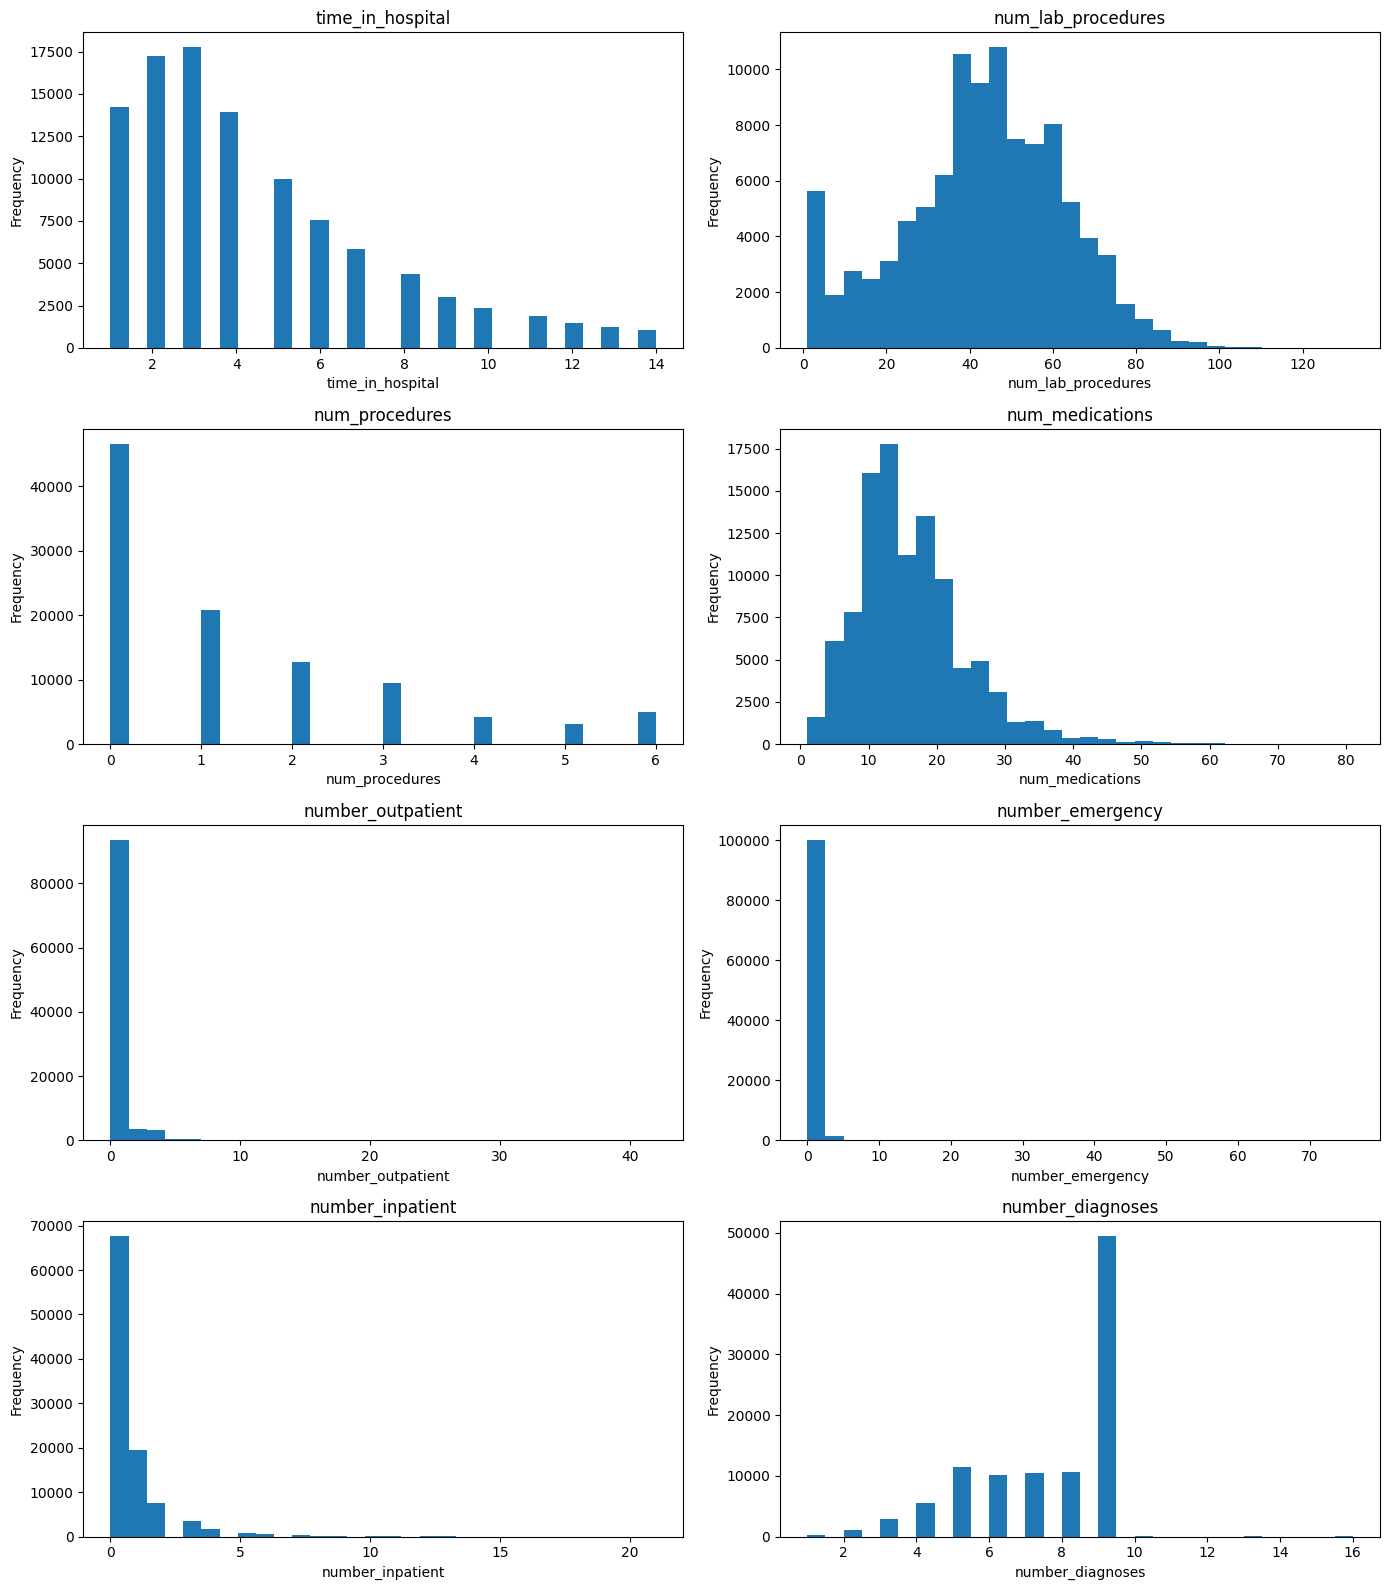

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, column in zip(axes.flat, numerical_features):
    ax.hist(df[column], bins=30)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## Categorical Feature Distribution 

In [16]:
print("Race distribution:")
print(df['race'].value_counts(dropna=False))

print("Gender Distribution:")
print(df['gender'].value_counts(dropna=False))

Race distribution:
race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64
Gender Distribution:
gender
Female     54708
Male       47055
Unknown        3
Name: count, dtype: int64


### Key Observations
* Caucasian encounters dominate the dataset, accounting for approximately 74.8% of encounters.
* AfricanAmerican encounters represent approximately 18.9%.
* The remaining racial categories each represent a relatively small share of the dataset.
* Gender distribution is relatively balanced, with Female encounters at 53.76% and Male encounters at 46.24%.
* Only 3 encounters have an unknown gender.

### Race Distribution

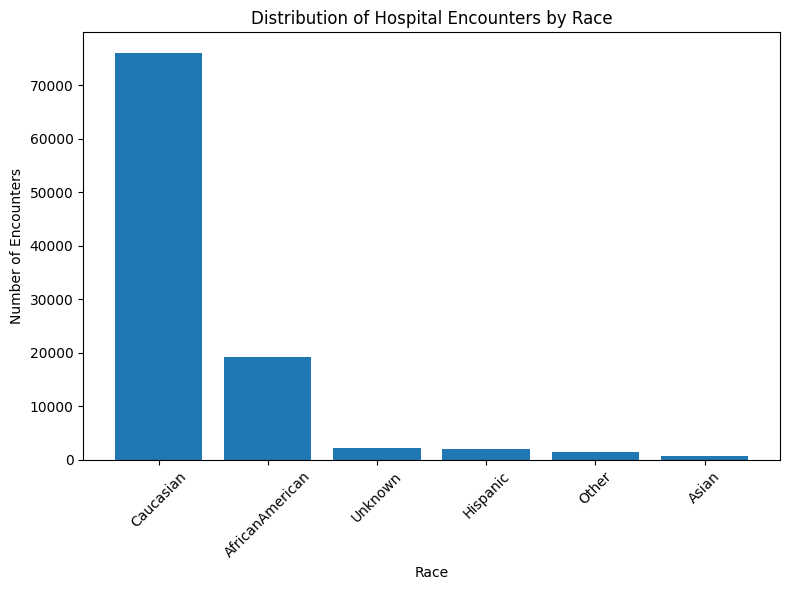

In [17]:
race_counts = df['race'].value_counts()

plt.figure(figsize=(8,6))
plt.bar(race_counts.index, race_counts.values)

plt.title('Distribution of Hospital Encounters by Race')
plt.xlabel('Race')
plt.ylabel('Number of Encounters')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Gender Distribution

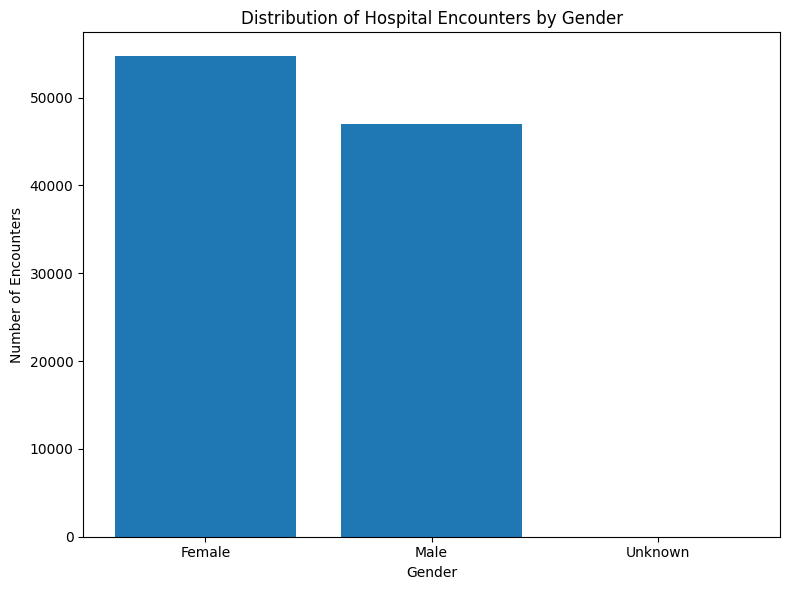

In [18]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(8,6))
plt.bar(gender_counts.index, gender_counts.values)

plt.title('Distribution of Hospital Encounters by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Encounters')
plt.tight_layout()
plt.show()

### Key Findings

The distribution of hospital encounters is not uniform across demographic groups. The dataset is predominantly composed of Caucasian encounters, followed by AfricanAmerican encounters, while Asian, Hispanic, Other, and Unknown categories account for comparatively smaller proportions.

The gender distribution is relatively balanced, although female encounters are somewhat more frequent than male encounters. Only a very small number of encounters have an unknown gender.

These distributions describe the composition of the dataset and should not be interpreted as population-level differences in diabetes prevalence or readmission risk.

## Age and 30-day Readmission Analysis

In [19]:
df['age'].value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [20]:
age_readmission = (
    df.groupby('age', observed=True)
    .agg(
        total_encounters=('readmitted_30d', 'size'),
        readmitted_30d_count=('readmitted_30d', 'sum'),
        readmission_rate=('readmitted_30d', 'mean')
    )
    .reset_index()
)

age_readmission['readmission_rate'] = (
    age_readmission['readmission_rate'] * 100
).round(2)

age_readmission

,age,total_encounters,readmitted_30d_count,readmission_rate
0,[0-10),161,3,1.86
1,[10-20),691,40,5.79
2,[20-30),1657,236,14.24
3,[30-40),3775,424,11.23
4,[40-50),9685,1027,10.60
5,[50-60),17256,1668,9.67
6,[60-70),22483,2502,11.13
7,[70-80),26068,3069,11.77
8,[80-90),17197,2078,12.08
9,[90-100),2793,310,11.10


### Key Findings
* The 20–30 age group has the highest observed readmission rate at 14.24%.
* However, it has only 1,657 encounters, substantially fewer than the older age groups. We should not conclude that younger adults inherently have the highest readmission risk from this table alone.
* Among the larger groups, readmission rates are relatively elevated in the 70–80 (11.77%) and 80–90 (12.08%) age groups.
* The 50–60 group has the lowest rate among the major adult age groups at 9.67%.
* The [0–10) and [10–20) groups have low observed rates, but their relatively small encounter counts make those estimates less stable.

### 30-day Readmission Rate by Age Group

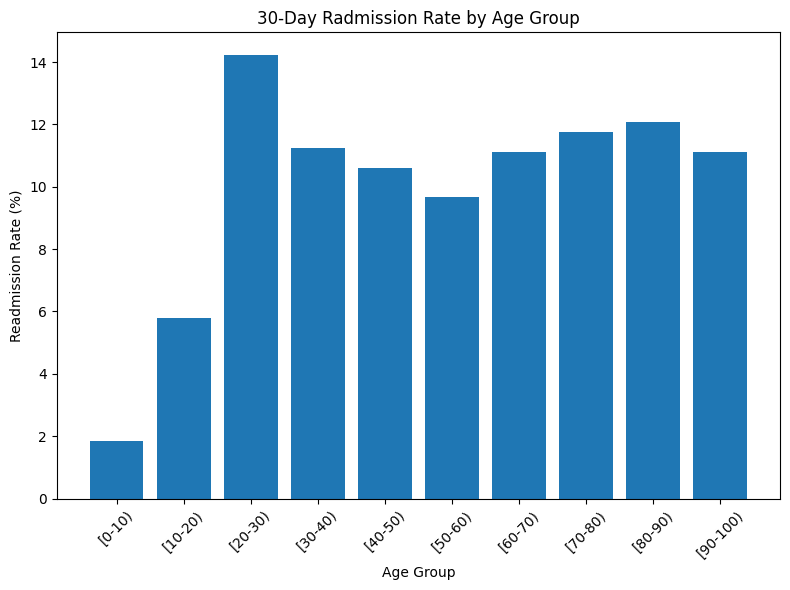

In [21]:
plt.figure(figsize=(8,6))

plt.bar(
    age_readmission['age'],
    age_readmission['readmission_rate']
)

plt.title('30-Day Radmission Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Key Finding

The 30-day readmission rate varies across age groups. The highest observed rate occurs among patients aged 20–30 years (14.24%), while the lowest occurs among patients aged 0–10 years (1.86%). Among the larger adult age groups, readmission rates generally range between approximately 9.7% and 12.1%.

The relatively high rate observed in the 20–30 age group should be interpreted cautiously because its encounter volume is considerably lower than that of the older age groups. The analysis demonstrates an association between age group and readmission rate, but does not establish age as a causal factor.

## Gender and 30-Day Readmission Analysis

In [22]:
gender_readmission = (
    df.groupby('gender', observed=True)
      .agg(
          total_encounters=('readmitted_30d', 'size'),
          readmitted_30d_count=('readmitted_30d', 'sum'),
          readmission_rate=('readmitted_30d', 'mean')
      )
      .reset_index()
)

gender_readmission['readmission_rate'] = (
    gender_readmission['readmission_rate'] * 100
).round(2)

gender_readmission

,gender,total_encounters,readmitted_30d_count,readmission_rate
0,Female,54708,6152,11.25
1,Male,47055,5205,11.06
2,Unknown,3,0,0.00


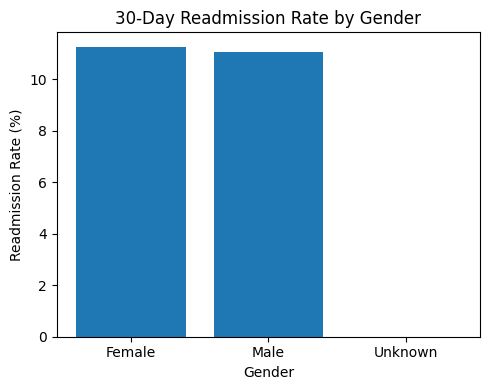

In [23]:
plt.figure(figsize=(5,4))

plt.bar(
    gender_readmission['gender'],
    gender_readmission['readmission_rate']
)

plt.title('30-Day Readmission Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Readmission Rate (%)')
plt.tight_layout()

plt.show()

### Key Finding

The 30-day readmission rates are very similar between female and male encounters. Female encounters have a slightly higher observed readmission rate of 11.25%, compared with 11.06% for male encounters, representing a difference of only 0.19 percentage points. The unknown-gender group contains only three encounters and is therefore not suitable for meaningful comparison.

Overall, gender does not show a substantial descriptive difference in 30-day readmission rates within this dataset.

## Race and 30-Day Readmission Analysis

In [24]:
race_readmission = (
    df.groupby('race', observed=True)
    .agg(
        total_encounters=('readmitted_30d', 'size'),
        readmitted_30d_count=('readmitted_30d', 'sum'),
        readmission_rate=('readmitted_30d', 'mean')
    )
    .reset_index()
)

race_readmission['readmission_rate'] = (
    race_readmission['readmission_rate'] * 100
).round(2)

race_readmission = race_readmission.sort_values('readmission_rate', ascending=False)

race_readmission

,race,total_encounters,readmitted_30d_count,readmission_rate
2,Caucasian,76099,8592,11.29
0,AfricanAmerican,19210,2155,11.22
3,Hispanic,2037,212,10.41
1,Asian,641,65,10.14
4,Other,1506,145,9.63
5,Unknown,2273,188,8.27


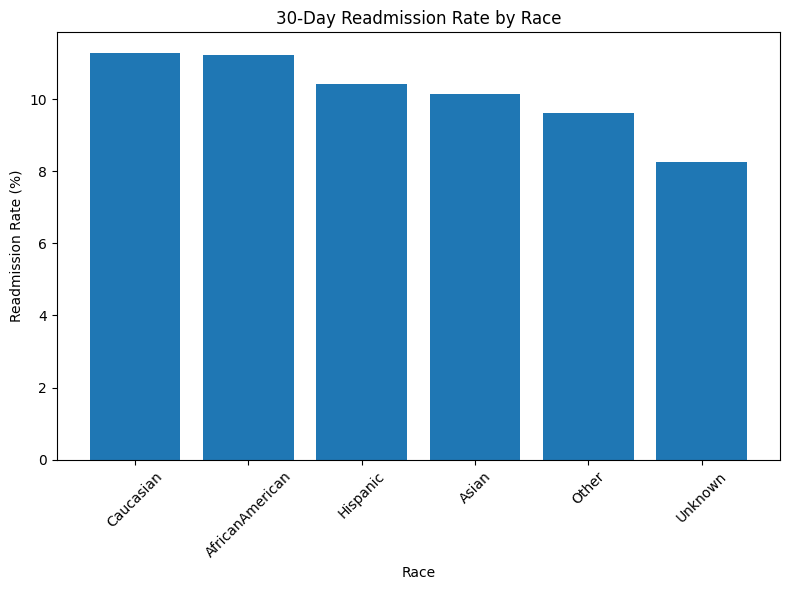

In [25]:
plt.figure(figsize=(8,6))

plt.bar(
    race_readmission['race'],
    race_readmission['readmission_rate']
)

plt.title('30-Day Readmission Rate by Race')
plt.xlabel('Race')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Key Findings
The observed 30-day readmission rate varies across racial groups, with Caucasian encounters showing the highest rate (11.29%) and the Unknown group showing the lowest rate (8.27%). The rate among AfricanAmerican encounters is very close to that of Caucasian encounters at 11.22%.

The differences should be interpreted cautiously because the racial groups have substantially different encounter volumes, particularly the smaller Asian and Other categories. These results describe differences in observed readmission rates within the dataset and do not establish race as a causal factor.

## Admission Type and 30-Day Readmission Analysis


In [26]:
admission_type_mapping = {
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'Not Available',
    6: 'Unknown',
    7: 'Trauma Center',
    8: 'Not Mapped'
}

df['admission_type'] = df['admission_type_id'].map(
    admission_type_mapping
).fillna('Unknown')

In [27]:
admission_readmission = (
    df.groupby('admission_type', observed=True)
      .agg(
          total_encounters=('readmitted_30d', 'size'),
          readmitted_30d_count=('readmitted_30d', 'sum'),
          readmission_rate=('readmitted_30d', 'mean')
      )
      .reset_index()
)

admission_readmission['readmission_rate'] = (
    admission_readmission['readmission_rate'] * 100
).round(2)

admission_readmission = admission_readmission.sort_values(
    'readmission_rate',
    ascending=False
)

admission_readmission

,admission_type,total_encounters,readmitted_30d_count,readmission_rate
1,Emergency,53990,6221,11.52
7,Urgent,18480,2066,11.18
6,Unknown,5291,586,11.08
0,Elective,18869,1961,10.39
3,Not Available,4785,495,10.34
2,Newborn,10,1,10.00
4,Not Mapped,320,27,8.44
5,Trauma Center,21,0,0.00


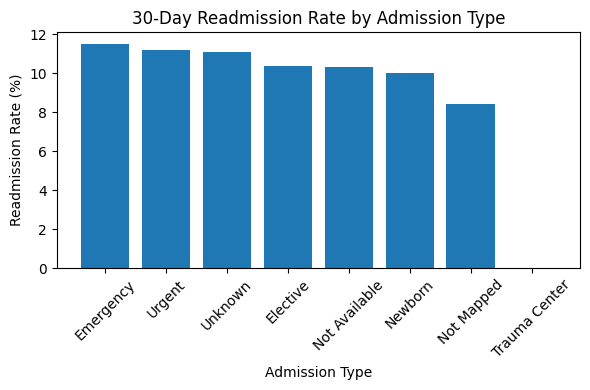

In [28]:
plt.figure(figsize=(6,4))

plt.bar(
    admission_readmission['admission_type'],
    admission_readmission['readmission_rate']
)

plt.title('30-Day Readmission Rate by Admission Type')
plt.xlabel('Admission Type')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

## Correlation Analysis

Correlation Analysis is performed to examine the strength and direction of linear relationships between numerical health variables.
The analysis focused on clinical, treatment, hospital, utilization, and encounter-related numerical featured rather than identifier and categorical-code variables.

In [29]:
correlation_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix.round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.00,0.32,0.19,0.47,-0.01,-0.01,0.07,0.22
num_lab_procedures,0.32,1.00,0.06,0.27,-0.01,-0.00,0.04,0.15
num_procedures,0.19,0.06,1.00,0.39,-0.02,-0.04,-0.07,0.07
num_medications,0.47,0.27,0.39,1.00,0.05,0.01,0.06,0.26
number_outpatient,-0.01,-0.01,-0.02,0.05,1.00,0.09,0.11,0.09
number_emergency,-0.01,-0.00,-0.04,0.01,0.09,1.00,0.27,0.06
number_inpatient,0.07,0.04,-0.07,0.06,0.11,0.27,1.00,0.10
number_diagnoses,0.22,0.15,0.07,0.26,0.09,0.06,0.10,1.00


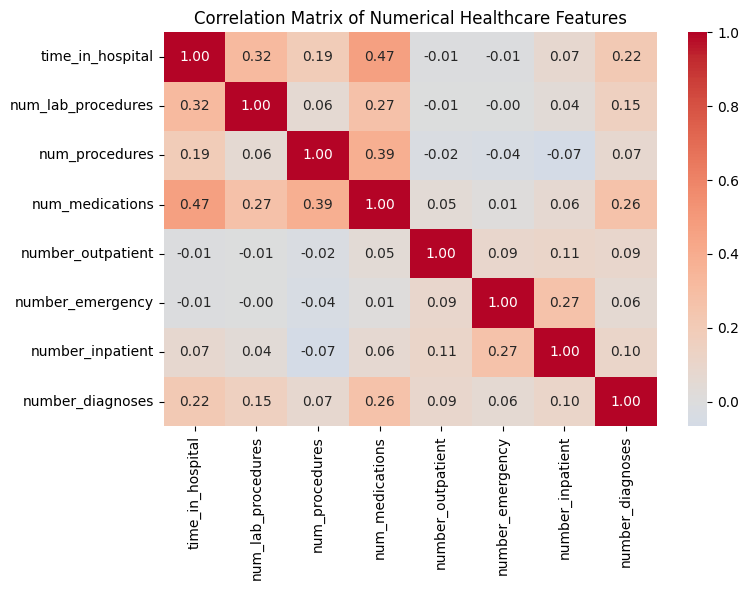

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center = 0
    )

plt.title('Correlation Matrix of Numerical Healthcare Features')
plt.tight_layout()
plt.show()

### Key Findings

The correlation analysis shows that most numerical healthcare features have weak to moderate linear relationships. The strongest positive correlation is between `time_in_hospital` and `num_medications` (0.47), followed by `num_procedures` and `num_medications` (0.39). `time_in_hospital` also shows a moderate positive relationship with `num_lab_procedures` (0.32).

Prior emergency and inpatient utilization have a moderate positive association (0.27), while most other relationships are relatively weak.

These correlations indicate associations between hospital stay, treatment intensity, and healthcare utilization, but they do not establish causal relationships.

## Medication Analysis

In [31]:
medication_change_counts = df['change'].value_counts(dropna=False)

medication_change_counts

change
No    54755
Ch    47011
Name: count, dtype: int64

In [32]:
medication_change_percentage =( df['change']
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

medication_change_percentage

change
No    53.8
Ch    46.2
Name: proportion, dtype: float64

### Key Finding

Medication changes were recorded in 47,011 hospital encounters (46.2%), while 54,755 encounters (53.8%) had no recorded medication change. Although encounters without medication changes were slightly more common, medication changes occurred in a substantial proportion of hospital encounters.

In [33]:
medication_summary = df['num_medications'].describe()

medication_summary

count    101766.000000
mean         16.021844
std           8.127566
min           1.000000
25%          10.000000
50%          15.000000
75%          20.000000
max          81.000000
Name: num_medications, dtype: float64

In [34]:
print("Mean:", round(df['num_medications'].mean(), 2))
print("Median:", df['num_medications'].median())
print("Maximum:", df['num_medications'].max())
print("Skewness:", round(df['num_medications'].skew(), 2))

Mean: 16.02
Median: 15.0
Maximum: 81
Skewness: 1.33


### Key Finding

Hospital encounters involved an average of 16.02 medications, with a median of 15 medications. The middle 50% of encounters involved between 10 and 20 medications. The distribution is positively skewed (skewness = 1.33), indicating that while most encounters have relatively moderate medication counts, a smaller number of encounters involve substantially higher medication burdens, with a maximum of 81 medications.

#### Medication Change Distribution

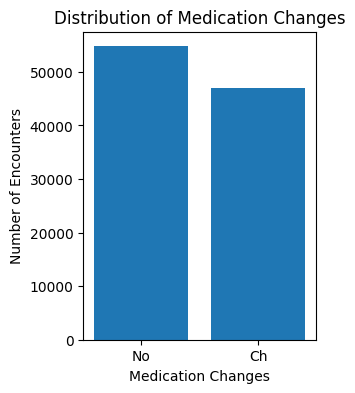

In [35]:
plt.figure(figsize=(3,4))

change_counts = df['change'].value_counts()

plt.bar(
    change_counts.index, change_counts.values
)

plt.title('Distribution of Medication Changes')
plt.xlabel('Medication Changes')
plt.ylabel('Number of Encounters')


plt.show()

#### Total Medication Distribution

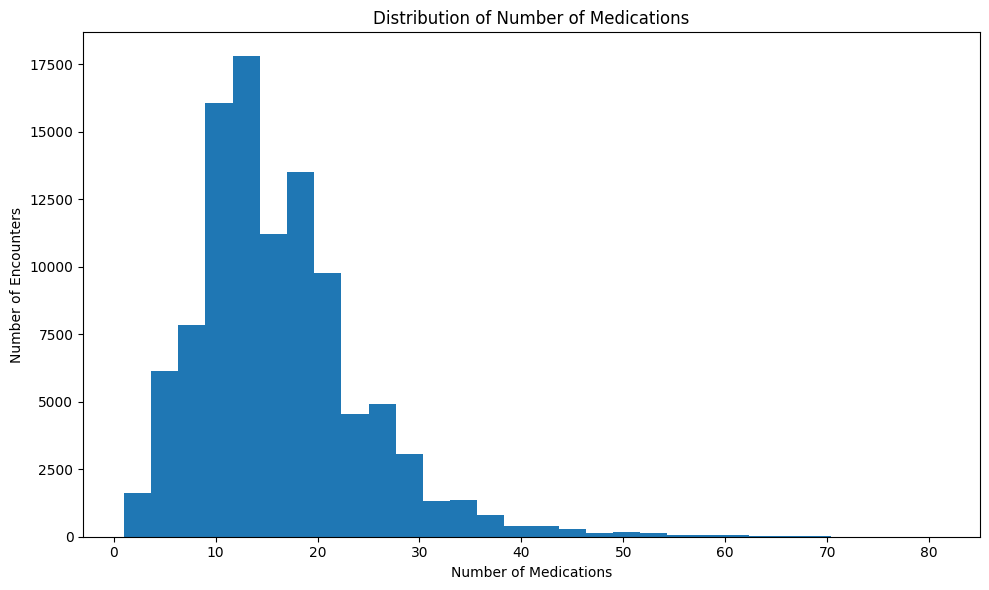

In [36]:
plt.figure(figsize=(10,6))

plt.hist(df['num_medications'], bins=30)

plt.title('Distribution of Number of Medications')
plt.xlabel('Number of Medications')
plt.ylabel('Number of Encounters')

plt.tight_layout()
plt.show()

### Overall Medication Analysis Finding

Medication changes were recorded in 46.2% of hospital encounters, while 53.8% had no recorded medication change. The number of medications per encounter is positively skewed, with most encounters involving approximately 10–20 medications. A smaller number of encounters have substantially higher medication counts, with the maximum reaching 81.

The distribution indicates that medication burden varies considerably across hospital encounters and may be relevant when examining patient complexity and 30-day readmission risk.

## Diagnosis Category Distribution

In [37]:
df[['diag_1', 'diag_2', 'diag_3']].head(10)

,diag_1,diag_2,diag_3
0,250.83,NaN,NaN
1,276,250.01,255
2,648,250,V27
3,8,250.43,403
4,197,157,250
5,414,411,250
6,414,411,V45
7,428,492,250
8,398,427,38
9,434,198,486


## Diagnosis Category Distribution

The primary diagnosis (`diag_1`) is categorized into broader clinical groups using ICD-9 code ranges. Grouping diagnosis codes into clinically meaningful categories provides a more interpretable view of the conditions represented in the hospital encounters.

In [38]:
def classify_icd9(code):
    if pd.isna(code):
        return 'Unknown'

    code = str(code).strip().upper()

    # V-codes and E-codes
    if code.startswith('V'):
        return 'Supplementry Factors'

    if code.startswith('E'):
        return 'External Causes'

    # Convert numeric ICD-9 code
    try:
        code_num = float(code)
    except ValueError:
        return 'Other'

    # ICD-9 clinical categories
    if 390 <= code_num <= 459 or 785 <= code_num <= 785.99:
        return 'Circulatory'

    elif 460 <= code_num <= 519 or 786 <= code_num <= 786.99:
        return 'Respiratory'

    elif 520 <= code_num <= 579 or 787 <= code_num <= 787.99:
        return 'Digestive'

    elif 250 <= code_num < 251:
        return 'Endocrine'

    elif 140 <= code_num <= 239:
        return 'Neplasmas'

    elif 580 <= code_num <= 629:
        return 'Genitourinary'

    elif 710 <= code_num <= 739:
        return 'Musculoskeletal'

    elif 800 <= code_num <= 999:
        return 'Injury'

    else:
        return 'Other' 

In [39]:
df['primary_diagnosis_category'] = df['diag_1'].apply(classify_icd9)

In [40]:
df['primary_diagnosis_category'].value_counts()

primary_diagnosis_category
Circulatory             30437
Other                   16566
Respiratory             14423
Digestive                9475
Endocrine                8757
Injury                   6974
Genitourinary            5078
Musculoskeletal          4957
Neplasmas                3433
Supplementry Factors     1644
Unknown                    21
External Causes             1
Name: count, dtype: int64

### Key Finding

Circulatory conditions represent the largest primary diagnosis category, accounting for approximately 29.9% of all hospital encounters. This is followed by Other (16.3%) and Respiratory conditions (14.2%). Digestive and Endocrine conditions account for approximately 9.3% and 8.6% of encounters, respectively.

The remaining diagnosis categories represent smaller proportions of encounters. Only 21 encounters have an Unknown primary diagnosis, indicating that missing primary diagnosis information is negligible after the diagnosis categorization.

The distribution demonstrates substantial variation in the types of primary conditions represented in the dataset and provides useful clinical context for subsequent readmission-risk analysis.

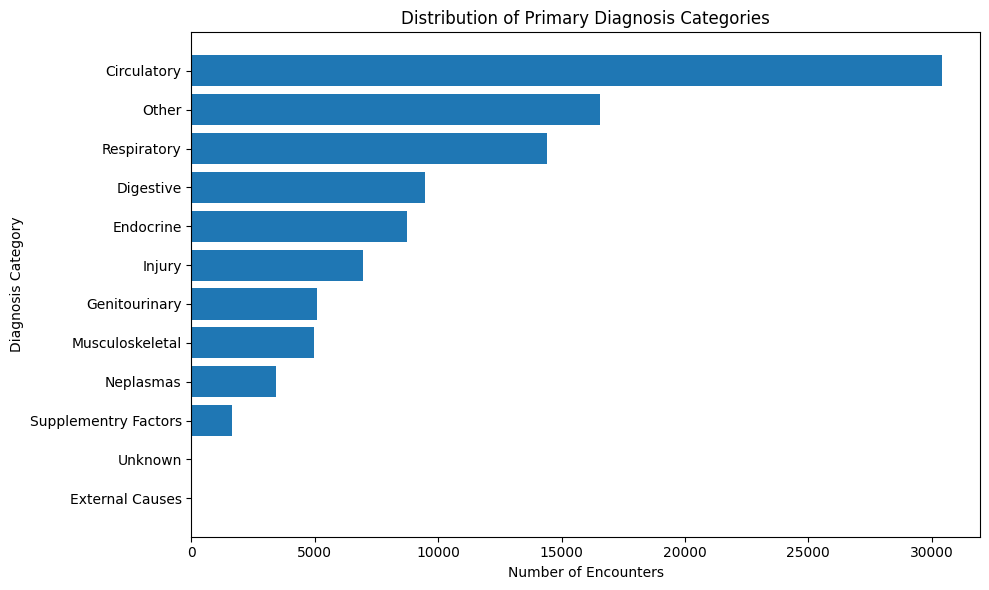

In [41]:
diagnosis_counts = (
    df['primary_diagnosis_category']
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10,6))

plt.barh(
    diagnosis_counts.index,
    diagnosis_counts.values
)

plt.title('Distribution of Primary Diagnosis Categories')
plt.xlabel('Number of Encounters')
plt.ylabel('Diagnosis Category')

plt.tight_layout()

plt.show()


In [42]:
df['admission_source_id'].value_counts().sort_index()

admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64

##### Admission-Source mapping

In [43]:
admission_source_mapping = {
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from a Hospital',
    5: 'Transfer from SNF',
    6: 'Transfer from Healthcare Facility',
    7: 'Emergency Room',
    8: 'Court/Law Enforcement',
    9: 'Not Available',
    10: 'Transfer from Critical Access Hospital',
    11: 'Normal Delivery',
    13: 'Sick Baby',
    14: 'Extramural Birth',
    17: 'Unknown',
    20: 'Not Mapped',
    22: 'Transfer from Hospital Inpatient/Same Facility',
    25: 'Transfer from Ambulatory Surgery Center'
}

#### * Distribution Calculation

In [44]:
admission_source_distribution = (
    df['admission_source_id']
    .map(admission_source_mapping)
    .fillna('Unknown')
    .value_counts()
    .reset_index()
)

admission_source_distribution.columns = [
    'Admission Source',
    'Encounter Count'
]

admission_source_distribution['Percentage'] = (
    admission_source_distribution['Encounter Count']
    / admission_source_distribution['Encounter Count'].sum()
    * 100
)

admission_source_distribution

,Admission Source,Encounter Count,Percentage
0,Emergency Room,57494,56.496276
1,Physician Referral,29565,29.051943
2,Unknown,6781,6.663326
3,Transfer from a Hospital,3187,3.131694
4,Transfer from Healthcare Facility,2264,2.224712
5,Clinic Referral,1104,1.084842
6,Transfer from SNF,855,0.840163
7,HMO Referral,187,0.183755
8,Not Mapped,161,0.158206
9,Not Available,125,0.122831


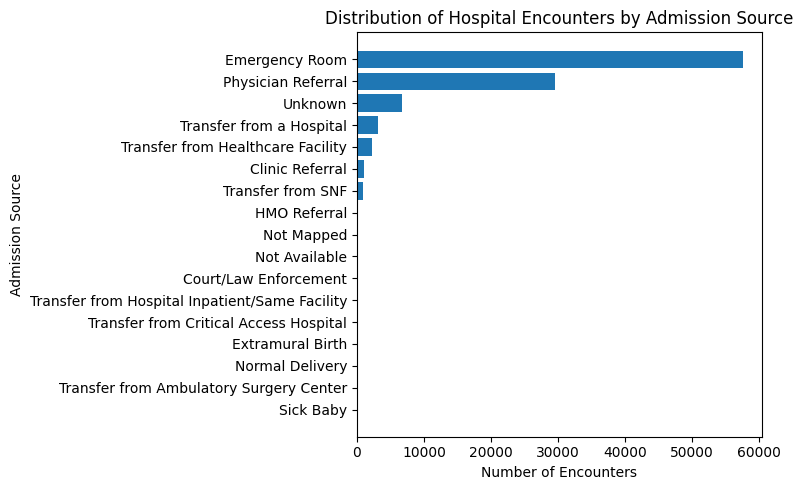

In [45]:
source_counts = (
    admission_source_distribution
    .sort_values('Encounter Count')
)

plt.figure(figsize=(8,5))

plt.barh(
    source_counts['Admission Source'],
    source_counts['Encounter Count']
)

plt.title('Distribution of Hospital Encounters by Admission Source')
plt.xlabel('Number of Encounters')
plt.ylabel('Admission Source')

plt.tight_layout()

plt.show()

In [46]:
df['discharge_disposition_id'].value_counts().sort_index()

discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

#### Discharge Disposition Mapping

In [57]:
discharge_disposition_mapping = {
    1: 'Discharged to Home',
    2: 'Short-Term Hospital',
    3: 'Skilled Nursing Facility',
    4: 'Intermediate Care Facility',
    5: 'Another Inpatient Care Institution',
    6: 'Home with Home Health Service',
    7: 'Left Aganist Medical Advice',
    8: 'Home with Home IV Provider',
    9: 'Admitted as Inpatient to this Hospital',
    10: 'Neonate Discharged to Another Hospital',
    11: 'Expired',
    12: 'Still a Patient / Reffered to This Institution',
    13: 'Hospice - Home',
    14: 'Hospice - Medical Facility',
    15: 'Medicare-Approved Swing Bed',
    16: 'Inpatient Rehabilitation Facility',
    17: 'Long-Term Care Hospital',
    18: 'Nursing Facility -  Medicaid Certified',
    19: 'Reserved',
    20: 'Not Mapped',
    21: 'Unknown',
    22: 'Inpatient Rehabilition Facility',
    23: 'Long-Term Care Hospital',
    24: 'Nursing Facility -     Medicaid Certified',
    25: 'Not Mapped',
    26: 'Unknown / Invalid',
    27: 'Federal Healthcare Facility',
    28: 'Hospital-Based Medicare-Approved Swing Bed',
    29: 'Other Inpatient Care Institution'
}

In [58]:
discharge_disposition_distribution = (
    df['discharge_disposition_id']
    .map(discharge_disposition_mapping)
    .fillna('Unknown')
    .value_counts()
    .reset_index()
)

discharge_disposition_distribution.columns = [
    'Discharge Disposition',
    'Encounter Count'
]

discharge_disposition_distribution['Percentage'] = (
    discharge_disposition_distribution['Encounter Count']
    / discharge_disposition_distribution['Encounter Count'].sum() * 100
)

discharge_disposition_distribution

,Discharge Disposition,Encounter Count,Percentage
0,Discharged to Home,60234,59.188727
1,Skilled Nursing Facility,13954,13.711849
2,Home with Home Health Service,12902,12.678105
3,Nursing Facility - Medicaid Certified,3691,3.626948
4,Short-Term Hospital,2128,2.091072
5,Inpatient Rehabilition Facility,1993,1.958414
6,Expired,1642,1.613505
7,Another Inpatient Care Institution,1184,1.163453
8,Not Mapped,991,0.973803
9,Intermediate Care Facility,815,0.800857


#### Visualization

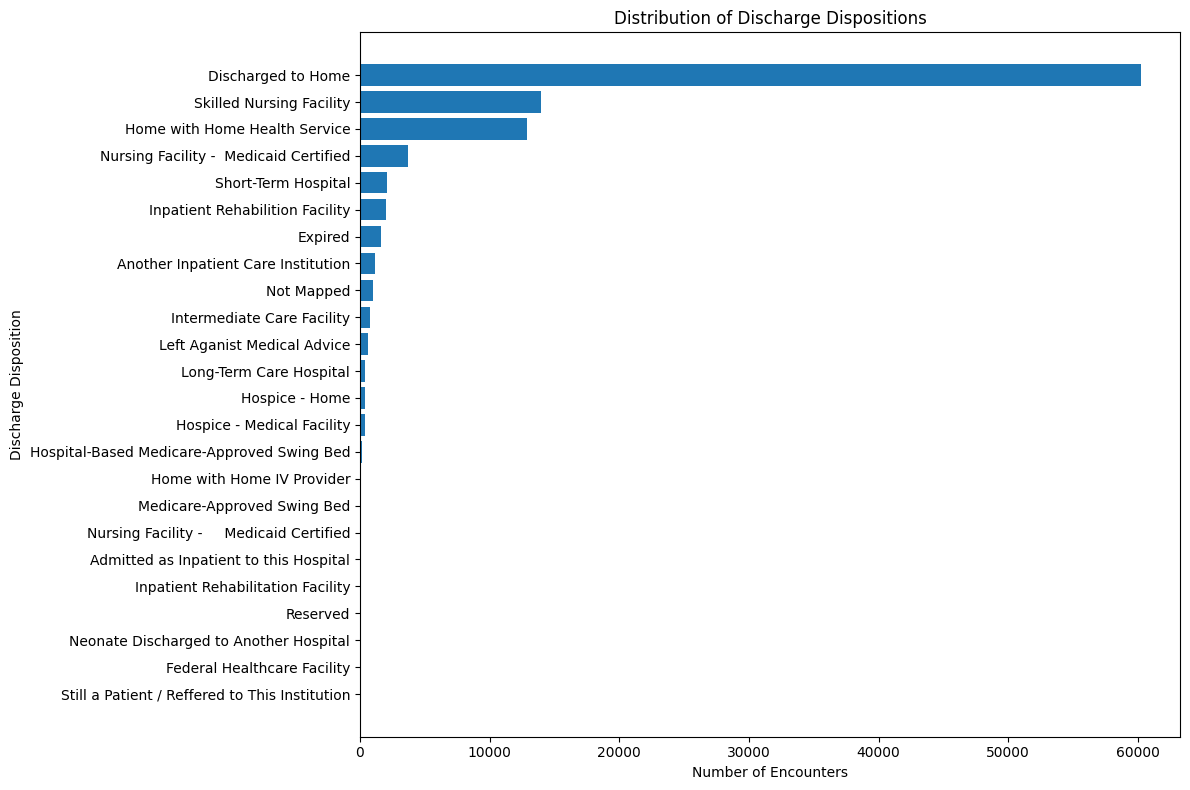

In [59]:
plt.figure(figsize=(12,8))

plt.barh(
    discharge_disposition_distribution['Discharge Disposition'][::-1],
    discharge_disposition_distribution['Encounter Count'][::-1]
)

plt.xlabel('Number of Encounters')
plt.ylabel('Discharge Disposition')
plt.title('Distribution of Discharge Dispositions')

plt.tight_layout()

plt.show()

### Key Findings
**Discharge Disposition Distribution:**
Discharge to home was the dominant disposition, accounting for 60,234 encounters, or approximately 59.19% of all encounters. This was followed by discharge to a skilled nursing facility with 13,954 encounters, and discharge to home with home health services with 12,902 encounters. Other notable categories included discharge to a short-term hospital, inpatient rehabilitation facilities, and hospice-related destinations. The distribution indicates that most encounters ended with discharge to home or post-acute care settings, although a smaller proportion involved institutional care, hospice, or death.


#### Top 10 discharge dispositions

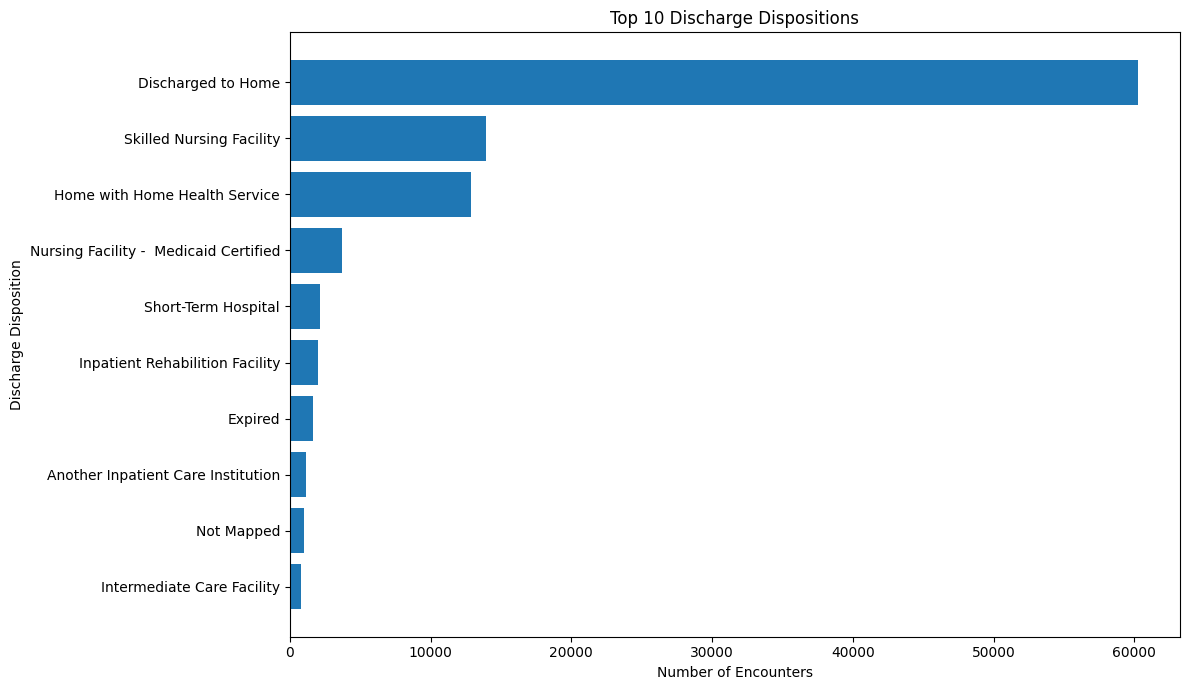

In [60]:
import matplotlib.pyplot as plt

# Correct the label typo
discharge_disposition_distribution['Discharge Disposition'] = (
    discharge_disposition_distribution['Discharge Disposition']
    .replace({'Dischargerd to Home': 'Discharged to Home'})
)

# Select top 10 categories
top_10_dispositions = discharge_disposition_distribution.head(10).copy()

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_dispositions['Discharge Disposition'][::-1],
    top_10_dispositions['Encounter Count'][::-1]
)

plt.xlabel('Number of Encounters')
plt.ylabel('Discharge Disposition')
plt.title('Top 10 Discharge Dispositions')

plt.tight_layout()
plt.show()

### Outlier Analysis

#### Numerical Variables to Examine

In [66]:
numerical_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

#### Calculating IQR-based outlier statistics

In [70]:
outlier_summary = []

for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(df) * 100
    )

    outlier_summary.append({
        'Feature': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound' : lower_bound,
        'upper_bound' : upper_bound,
        'Outlier Count' : outlier_count,
        'outlier Percentage' : outlier_percentage
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

display(outlier_summary_df)

,Feature,Q1,Q3,IQR,Lower Bound,upper_bound,Outlier Count,outlier Percentage
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.212920
1,num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143,0.140518
2,num_procedures,0.0,2.0,2.0,-3.0,5.0,4954,4.868031
3,num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.512627
4,number_outpatient,0.0,0.0,0.0,0.0,0.0,16739,16.448519
5,number_emergency,0.0,0.0,0.0,0.0,0.0,11383,11.185465
6,number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049,6.926675
7,number_diagnoses,6.0,9.0,3.0,1.5,13.5,281,0.276124


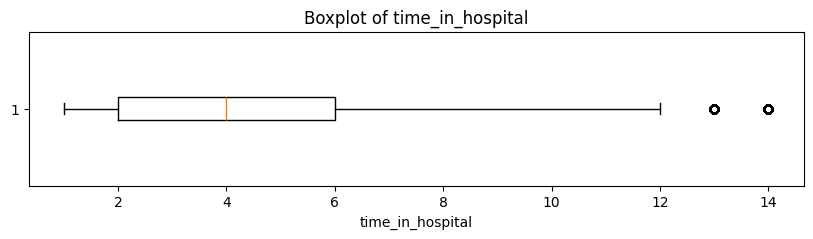

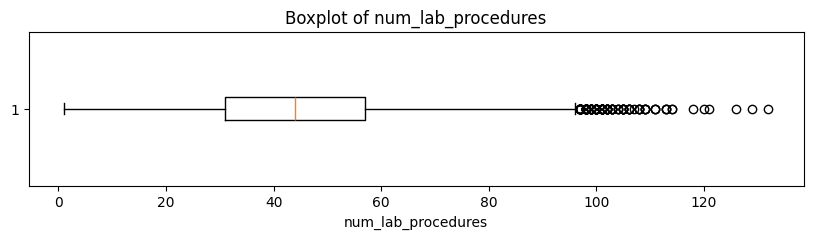

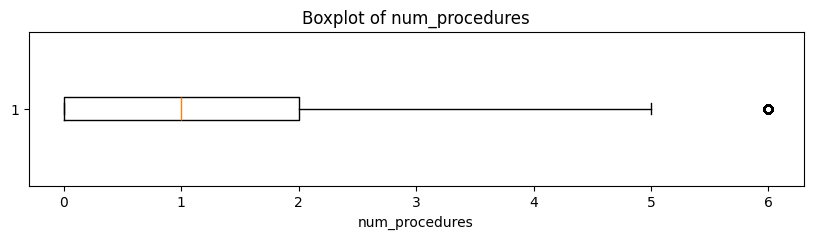

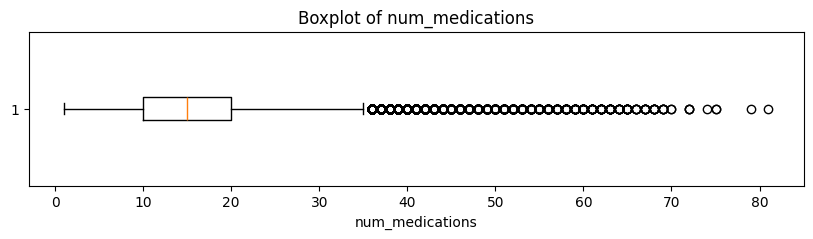

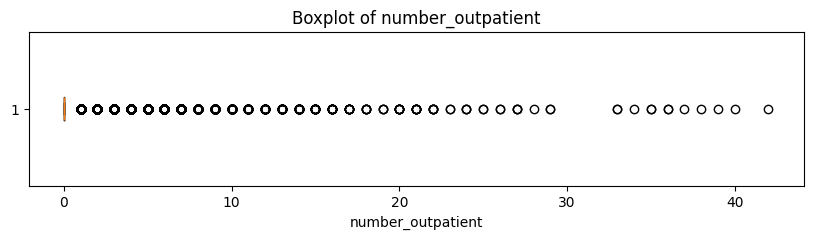

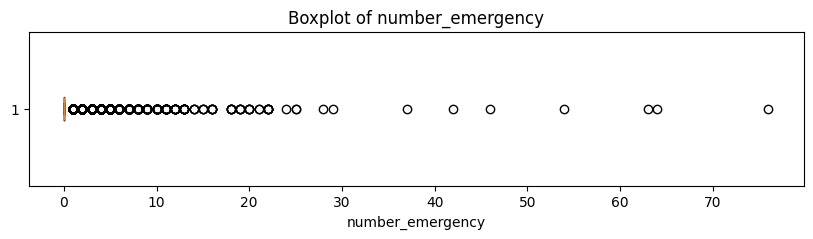

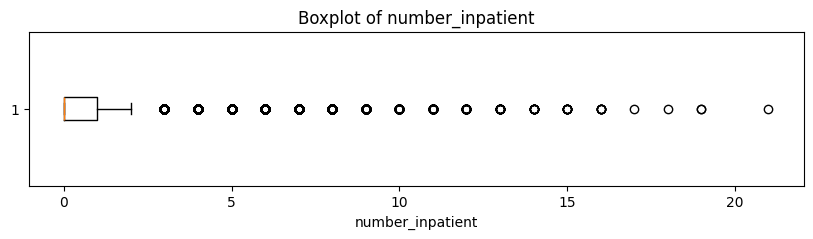

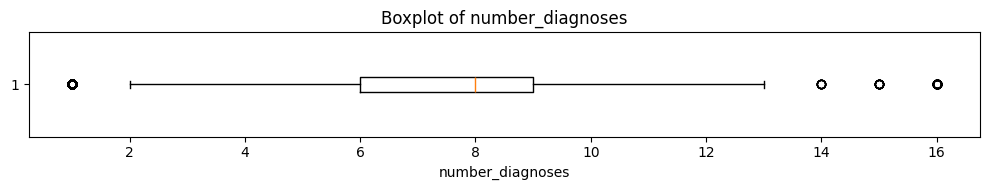

In [77]:
for column in numerical_features:
    plt.figure(figsize=(10,2))

    plt.boxplot(
        df[column].dropna(),
        vert=False
    )

    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)

plt.tight_layout()

plt.show()

### Interpretation

**Boxplot-Based Outlier Analysis:**
Boxplots were used to visually examine the distribution and potential outliers of numerical features. The prior healthcare utilization variables—number_outpatient, number_emergency, and number_inpatient—showed pronounced right-skewness and numerous observations beyond the upper whiskers. This reflects a smaller group of patients with frequent prior healthcare utilization. The variables num_medications, num_procedures, and time_in_hospital also contained some higher-end observations, while num_lab_procedures and number_diagnoses showed comparatively limited outlier presence.

These observations were retained because they may represent genuine clinical complexity or healthcare utilization patterns rather than data-entry errors. Outlier treatment, if required, will be evaluated during model development using domain knowledge and model performance rather than automatic deletion.

## **EDA Summary and Key Findings**

### 1. Dataset and Data Quality

The dataset contains 101,766 hospital encounter records and 51 variables, including the engineered binary target `readmitted_30d`.

The target was defined as:

- `1`: Readmission within 30 days
- `0`: No readmission or readmission after 30 days

The target distribution is imbalanced:

- No 30-day readmission: 90,409 encounters (88.84%)
- 30-day readmission: 11,357 encounters (11.16%)

The dataset contained no duplicate records. Missing values were concentrated in `weight`, `max_glu_serum`, and `A1Cresult`. Diagnosis fields had comparatively low levels of missingness.

### 2. Demographic Findings

Caucasian encounters represented the largest racial group, followed by African American encounters. Female encounters were slightly more common than male encounters.

The age-group analysis showed that readmission rates varied across age brackets. The `[20-30)` age group had a comparatively higher observed readmission rate, while the `[0-10)` and `[10-20)` groups had smaller sample sizes. Therefore, rates from small age groups should be interpreted cautiously.

### 3. Hospital Utilization Findings

Emergency Room admissions were the most common admission source, accounting for approximately 56.50% of all encounters. Physician referrals represented approximately 29.05%. Together, these two sources accounted for approximately 85.55% of encounters.

Discharge to home was the dominant discharge disposition, followed by discharge to skilled nursing facilities and home with home health services.

### 4. Clinical Findings

Circulatory conditions were the most common primary diagnosis category, followed by Other, Respiratory, Digestive, and Endocrine categories.

The diagnosis categories were created by grouping ICD-9 diagnosis codes into broader clinical classifications. These categories describe the distribution of diagnoses and should not be interpreted as independent causes of readmission.

### 5. Medication and Treatment Findings

The average number of medications per encounter was approximately 16, while the median was 15. The medication distribution was right-skewed, indicating that some encounters involved substantially higher medication counts.

Approximately 53.8% of encounters had no medication change, while approximately 46.2% recorded a medication change.

### 6. Correlation Findings

The strongest observed numerical relationships included:

- `time_in_hospital` and `num_medications`
- `num_procedures` and `num_medications`
- `time_in_hospital` and `num_lab_procedures`
- `number_emergency` and `number_inpatient`

These relationships represent associations between variables. Correlation does not establish causation.

### 7. Outlier Findings

The IQR method and boxplots identified potential outliers, particularly in prior outpatient, emergency, and inpatient utilization variables.

These variables were strongly right-skewed because most encounters had zero prior visits, while a smaller group had multiple prior healthcare encounters.

The potential outliers were retained because they may represent genuine patient complexity or high healthcare utilization rather than data errors.

## Overall EDA Conclusion

The exploratory analysis indicates that 30-day readmission is an imbalanced clinical outcome associated with a complex combination of demographic, admission, diagnosis, treatment, and prior-utilization characteristics.

The dataset contains useful information for developing a readmission-risk model, particularly in the areas of prior healthcare utilization, diagnosis categories, medication burden, hospital stay characteristics, and admission-related variables.

However, the observed patterns are descriptive and unadjusted. They should not be interpreted as causal relationships or definitive patient-level risk factors without further statistical analysis and predictive modeling.

The next phase will focus on preparing the validated dataset for Tableau visualization and, subsequently, machine learning. Feature engineering, leakage assessment, class imbalance handling, and evaluation metrics such as Recall, Precision, and PR-AUC will be important during model development.